# Practical Assignment 4: Classification Models
### Classification of Food Inflation Levels using SVM, Decision Tree, KNN and Naïve Bayes

| | |
|---|---|
| **Name** | Tushar Kaldate |
| **Roll No.** | 47 |
| **Batch** | A2 |
| **PRN** | 202401040191 |
| **Selected Instance** | Food Inflation Prediction |
| **GitHub Repository** | [https://github.com/tusharkkp/AI-ML/](https://github.com/tusharkkp/AI-ML/) |

## 1. Aim

To develop classification models using **Support Vector Machine (SVM), Decision Tree, K-Nearest Neighbours (KNN) and Naïve Bayes** on the *Food Inflation Prediction* instance, to evaluate each model using **accuracy, precision, recall, F1-score and loss (log-loss)**, and to summarise a **comparative analysis** that discusses the suitability of each algorithm for different classification tasks.

## 2. Experiment Objectives

1. To understand the problem of supervised classification and frame *food inflation* as a multi-class classification task (**Low / Moderate / High**).
2. To perform data preparation: handling missing values, scaling numeric features, encoding categorical features, and a stratified train/test split.
3. To implement and tune four classifiers (SVM, Decision Tree, KNN, Gaussian Naïve Bayes) using cross-validated hyper-parameter search.
4. To evaluate the models with accuracy, precision, recall, F1-score, confusion matrix, ROC-AUC and log-loss.
5. To study over-fitting / under-fitting through train-vs-test comparison, validation curves and learning curves.
6. To compare the algorithms and discuss which algorithm suits which kind of classification task.

## 3. Experiment Outcome

After completing this experiment the student will be able to:

* Build an end-to-end classification pipeline in Python using `scikit-learn` (pre-processing + model in a single `Pipeline`).
* Tune hyper-parameters (kernel, `C`, `gamma`, tree depth, `k`, `var_smoothing`) with `GridSearchCV`.
* Interpret precision, recall, F1-score, confusion matrices, ROC curves and log-loss for multi-class problems.
* Explain the bias–variance behaviour of the four algorithms.
* Select a suitable algorithm for a given classification task by considering data size, dimensionality, noise, interpretability and training/prediction cost.

## 4. Conceptual Details

### 4.1 Classification
Classification is a **supervised learning** task in which a model learns a mapping $f : X \rightarrow y$ from labelled examples, where $y$ is a *discrete* class label. In this experiment the label is the **food-inflation level** (Low, Moderate, High) and the inputs are macro-economic, climate and market indicators.

### 4.2 Algorithms

**(a) Support Vector Machine (SVM)** – finds the hyperplane that maximises the margin between classes.
$$\min_{w,b,\xi}\ \frac12\|w\|^2 + C\sum_i \xi_i \quad \text{s.t.}\quad y_i(w^\top\phi(x_i)+b)\ge 1-\xi_i,\ \ \xi_i\ge 0$$
The *kernel trick* ($K(x,x')=\phi(x)^\top\phi(x')$, e.g. RBF $=\exp(-\gamma\|x-x'\|^2)$) lets SVM model non-linear boundaries. `C` controls the margin/misclassification trade-off. Multi-class is handled by one-vs-one.

**Illustrations - SVM**

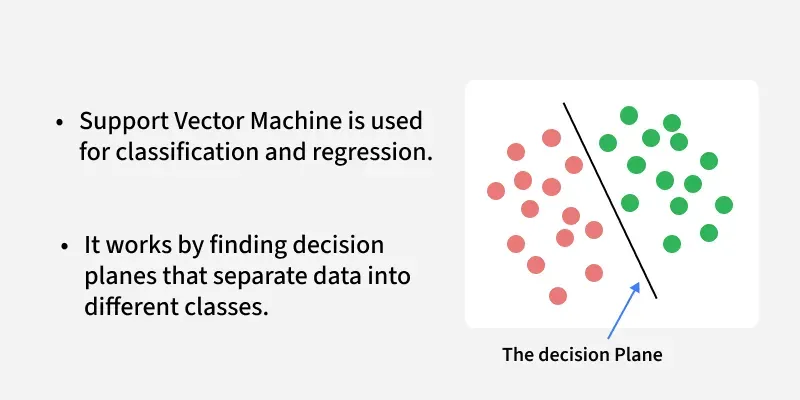

*Figure 1: SVM separates the classes with a decision plane.*

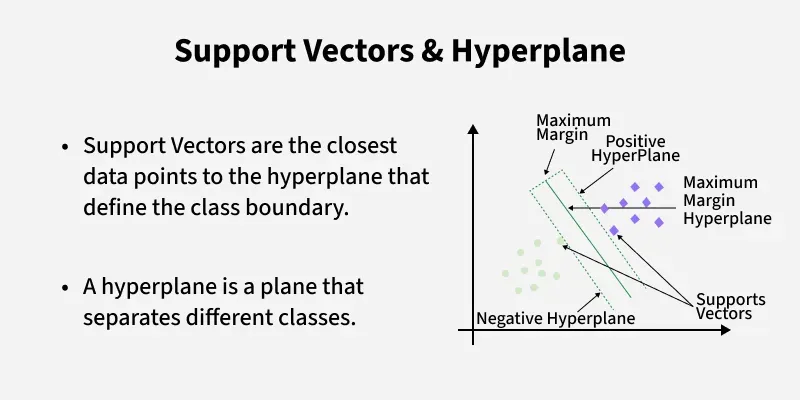

*Figure 2: Support vectors, maximum margin and the separating hyperplane.*

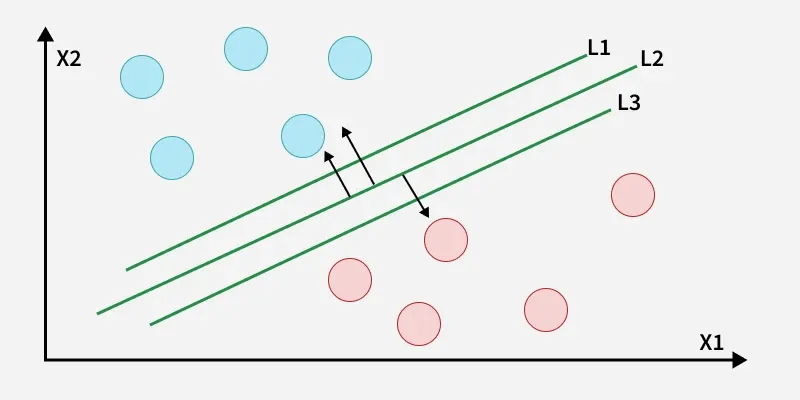

*Figure 3: Candidate separating lines (L1, L2, L3) - SVM chooses the one with the maximum margin.*

**(b) Decision Tree** – recursively splits the data on the feature/threshold that gives the largest impurity reduction.
$$\text{Gini}=1-\sum_k p_k^2 \qquad\qquad \text{Entropy}=-\sum_k p_k\log_2 p_k$$
Highly interpretable (if-then rules), needs no scaling, but can **over-fit** unless depth / leaf size is limited.

**Illustrations - Decision Tree**

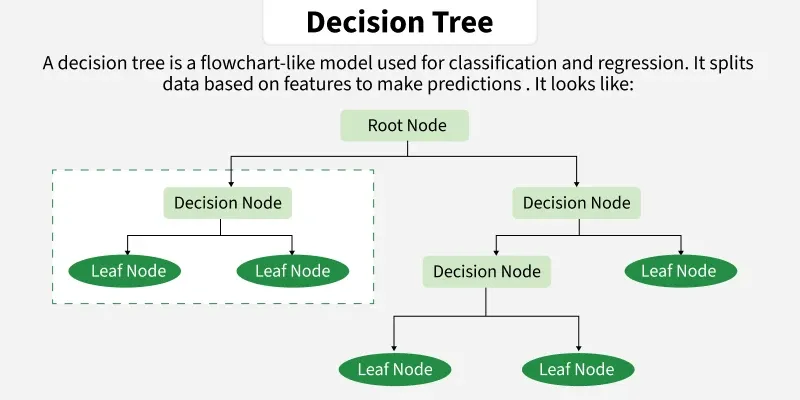

*Figure 4: Structure of a decision tree (root, decision nodes and leaf nodes).*

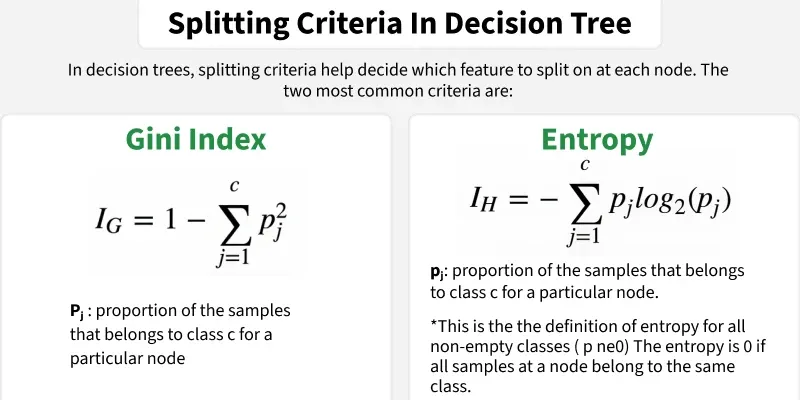

*Figure 5: Splitting criteria of a decision tree - Gini index and Entropy.*

**(c) K-Nearest Neighbours (KNN)** – a lazy, instance-based learner. A point is assigned the majority class among its $k$ nearest training points under a distance such as Euclidean $d(x,x')=\sqrt{\sum_j (x_j-x'_j)^2}$. Small $k$ → low bias / high variance; large $k$ → high bias / low variance. Needs **feature scaling**.

**Illustration - KNN**

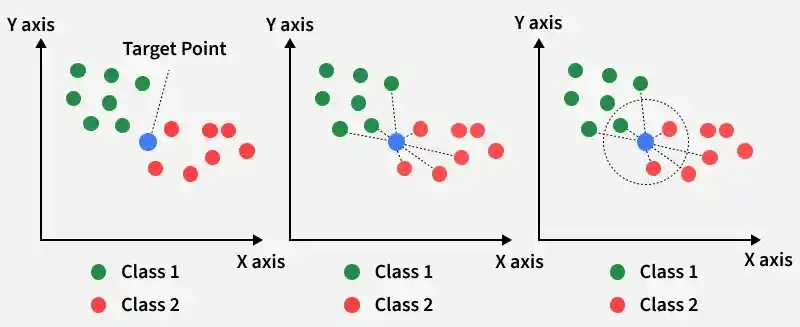

*Figure 6: KNN classifies the target point by the majority class of its nearest neighbours.*

**(d) Naïve Bayes** – applies Bayes' theorem with the *conditional-independence* assumption between features:
$$P(y\mid x_1,\dots,x_n)\ \propto\ P(y)\prod_{j=1}^{n}P(x_j\mid y)$$
Gaussian NB models each $P(x_j\mid y)$ as a normal distribution. Extremely fast and works with little data, but performs poorly when features are strongly correlated.

**Illustration - Naive Bayes**

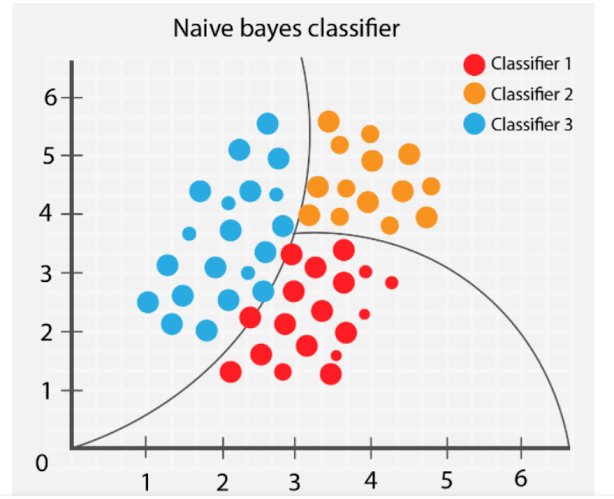

*Figure 7: Naive Bayes classifier separating three classes with probabilistic decision boundaries.*

### 4.3 Evaluation metrics
For a class with true positives $TP$, false positives $FP$, false negatives $FN$ and true negatives $TN$:

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad \text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN},\quad F_1=\frac{2\cdot P\cdot R}{P+R}$$

**Loss (Log-loss / cross-entropy)** measures the quality of the predicted *probabilities* (lower is better):
$$\mathcal{L}=-\frac1N\sum_{i=1}^{N}\sum_{k=1}^{K}y_{ik}\log\,\hat p_{ik}$$

For the multi-class problem precision, recall and F1 are reported as **macro-averages** (unweighted mean over classes) and weighted averages. **ROC-AUC** is computed one-vs-rest.

### 4.4 About the dataset (Food Inflation Prediction)
Each record describes one month in one region and contains the drivers that economists associate with food-price inflation. The target `Inflation_Level` is obtained by binning the food-inflation rate into **Low**, **Moderate** and **High**.

| Feature | Meaning |
|---|---|
| `Prev_Month_Inflation` | Food inflation in the previous month (%) |
| `Fuel_Price_Change` | Change in fuel price (%) |
| `Transport_Cost_Index` | Freight / transport cost index |
| `Global_Food_Price_Index` | International food price index |
| `Fertilizer_Price_Index` | Fertilizer price index |
| `Exchange_Rate_Depreciation` | Currency depreciation vs USD (%) |
| `Rainfall_Deviation` | Rainfall deviation from normal (%) |
| `Crop_Yield_Index` | Crop yield index (100 = normal) |
| `Money_Supply_Growth` | Money supply (M3) growth (%) |
| `Wage_Growth` | Rural wage growth (%) |
| `Region` | Urban / Semi-Urban / Rural |
| `Season` | Winter / Summer / Monsoon / Post-Monsoon |
| **`Inflation_Level`** | **Target: Low / Moderate / High** |

> **Data note:** the dataset is generated inside the notebook with a fixed random seed (`47`, my roll number) by a documented economic relationship plus noise, so the notebook runs anywhere without downloading files and always reproduces the same numbers. To use a real CSV instead, set `CSV_PATH` in the data cell (it must contain the columns above, or any numeric/categorical features plus a target column named `Inflation_Level`).

## 5. Algorithm / Flowchart

```
                         ┌────────────────────────────┐
                         │   START                    │
                         └─────────────┬──────────────┘
                                       ▼
                         ┌────────────────────────────┐
                         │ Load Food-Inflation data   │
                         └─────────────┬──────────────┘
                                       ▼
                         ┌────────────────────────────┐
                         │ EDA: shape, missing values,│
                         │ class balance, correlation │
                         └─────────────┬──────────────┘
                                       ▼
                         ┌────────────────────────────┐
                         │ Stratified train/test split│
                         │ (80 % / 20 %)              │
                         └─────────────┬──────────────┘
                                       ▼
          ┌────────────────────────────────────────────────────────┐
          │ Pre-processing (fit on TRAIN only)                     │
          │  numeric : median imputation → StandardScaler          │
          │  category: most-frequent imputation → One-Hot encoding │
          └────────────────────────────┬───────────────────────────┘
                                       ▼
     ┌───────────────┬─────────────────┼─────────────────┬────────────────┐
     ▼               ▼                 ▼                 ▼
 ┌────────┐     ┌──────────┐      ┌────────┐       ┌────────────┐
 │  SVM   │     │ Decision │      │  KNN   │       │ Naïve Bayes│
 │        │     │  Tree    │      │        │       │            │
 └───┬────┘     └────┬─────┘      └───┬────┘       └─────┬──────┘
     └───────────────┴─────────┬──────┴──────────────────┘
                               ▼
              ┌──────────────────────────────────┐
              │ GridSearchCV (5-fold, F1-macro)  │
              │ → best hyper-parameters per model│
              └────────────────┬─────────────────┘
                               ▼
              ┌──────────────────────────────────┐
              │ Predict on unseen TEST set       │
              └────────────────┬─────────────────┘
                               ▼
              ┌──────────────────────────────────┐
              │ Metrics: Accuracy, Precision,    │
              │ Recall, F1, Log-loss, ROC-AUC,   │
              │ Confusion matrix                 │
              └────────────────┬─────────────────┘
                               ▼
              ┌──────────────────────────────────┐
              │ Over-fitting check + 10-fold CV  │
              │ + learning / validation curves   │
              └────────────────┬─────────────────┘
                               ▼
              ┌──────────────────────────────────┐
              │ Comparative analysis & suitability│
              └────────────────┬─────────────────┘
                               ▼
                         ┌───────────┐
                         │   STOP    │
                         └───────────┘
```

**Step-wise algorithm**

1. Load the dataset and inspect it.
2. Split into train (80 %) and test (20 %) using stratified sampling so class proportions are preserved.
3. Build a `ColumnTransformer` (impute + scale numeric, impute + one-hot categorical) and wrap it with each classifier in a `Pipeline` – this prevents data leakage.
4. Tune each classifier with 5-fold `GridSearchCV` optimising macro-F1.
5. Evaluate the tuned models on the held-out test set with all required metrics.
6. Diagnose bias/variance with train-vs-test scores, validation curves and learning curves; confirm stability with 10-fold cross-validation.
7. Compare algorithms and write the findings.

## 6. Python Code
### 6.1 Import libraries

In [1]:
import warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate, validation_curve, learning_curve)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             log_loss, roc_auc_score, roc_curve, auc,
                             confusion_matrix, classification_report)

RANDOM_STATE = 47            # my roll number -> reproducible results
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print("Libraries imported successfully")

Libraries imported successfully


### 6.2 Load the Food Inflation dataset
The data is generated with a fixed seed from an explicit economic relationship (inflation depends on previous inflation, fuel, transport, global food prices, currency depreciation, money supply, wages, rainfall/crop yield, season and region, plus noise and a few non-linear effects such as a drought penalty). The continuous inflation rate is then binned into three classes. A small fraction of values is blanked out to mimic real-world missing data.

In [2]:
CSV_PATH = None   # e.g. "food_inflation.csv" -> to use a real dataset with a column named 'Inflation_Level'

def make_food_inflation_data(n=1500, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    fuel      = rng.normal(2.0, 5.0, n)                                   # fuel price change %
    transport = 100 + 0.6 * fuel + rng.normal(0, 3, n)                    # correlated with fuel
    gfood     = rng.normal(110, 15, n)                                    # global food price index
    fert      = 45 + 0.5 * gfood + rng.normal(0, 6, n)                    # correlated with global food prices
    fx        = rng.normal(1.0, 3.0, n)                                   # currency depreciation %
    rain      = rng.normal(0, 15, n)                                      # rainfall deviation %
    yield_idx = 100 + 0.25 * rain + rng.normal(0, 8, n)                   # crop yield depends on rain
    money     = rng.normal(8, 2.5, n)                                     # money supply growth %
    wage      = rng.normal(6, 2.0, n)                                     # wage growth %
    prev      = rng.normal(5.5, 2.5, n)                                   # previous month inflation %
    region    = rng.choice(["Urban", "Semi-Urban", "Rural"], n, p=[0.40, 0.30, 0.30])
    season    = rng.choice(["Winter", "Summer", "Monsoon", "Post-Monsoon"], n)

    season_eff = pd.Series(season).map({"Winter": -0.4, "Summer": 0.2, "Monsoon": 0.6, "Post-Monsoon": -0.1}).values
    region_eff = pd.Series(region).map({"Urban": 0.3, "Semi-Urban": 0.0, "Rural": -0.2}).values

    rate = (0.9 + 0.35 * prev + 0.10 * fuel + 0.08 * (transport - 100) + 0.025 * (gfood - 110)
            + 0.35 * fx + 0.12 * money + 0.10 * wage - 0.06 * (yield_idx - 100)
            + 0.08 * np.maximum(-rain - 15, 0)          # drought penalty (non-linear)
            + 0.02 * fx * fuel                          # interaction
            + season_eff + region_eff + rng.normal(0, 1.0, n))

    low_cut, high_cut = np.percentile(rate, [40, 75])
    level = np.where(rate < low_cut, "Low", np.where(rate < high_cut, "Moderate", "High"))

    df = pd.DataFrame({
        "Prev_Month_Inflation": prev, "Fuel_Price_Change": fuel, "Transport_Cost_Index": transport,
        "Global_Food_Price_Index": gfood, "Fertilizer_Price_Index": fert,
        "Exchange_Rate_Depreciation": fx, "Rainfall_Deviation": rain, "Crop_Yield_Index": yield_idx,
        "Money_Supply_Growth": money, "Wage_Growth": wage, "Region": region, "Season": season,
        "Inflation_Level": level,
    }).round(3)

    # blank out ~2 % of a few numeric columns (missing data)
    for col in ["Fuel_Price_Change", "Rainfall_Deviation", "Wage_Growth", "Crop_Yield_Index", "Money_Supply_Growth"]:
        df.loc[rng.random(n) < 0.02, col] = np.nan
    return df

df = pd.read_csv(CSV_PATH) if CSV_PATH else make_food_inflation_data()
print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (1500, 13)


,Prev_Month_Inflation,Fuel_Price_Change,Transport_Cost_Index,Global_Food_Price_Index,Fertilizer_Price_Index,Exchange_Rate_Depreciation,Rainfall_Deviation,Crop_Yield_Index,Money_Supply_Growth,Wage_Growth,Region,Season,Inflation_Level
0,4.497,-1.332,95.320,116.347,108.941,-0.821,1.085,117.130,11.356,6.808,Urban,Winter,Low
1,3.785,2.487,102.582,89.106,87.483,2.133,-4.658,NaN,6.831,4.664,Rural,Post-Monsoon,Low
2,2.854,-7.498,94.032,103.925,96.455,1.513,12.893,100.935,12.605,2.567,Rural,Post-Monsoon,Low
3,7.262,-7.700,93.911,105.804,102.366,-0.922,21.137,112.565,7.083,4.867,Rural,Monsoon,Low
4,5.912,-5.053,97.799,100.282,94.656,0.823,-3.562,89.538,12.526,5.728,Rural,Post-Monsoon,Low
5,2.538,-2.003,96.768,111.954,103.199,-5.804,12.953,106.503,8.842,9.061,Urban,Monsoon,Low
6,4.649,-1.671,99.840,88.893,81.995,2.603,7.108,99.610,7.633,3.221,Semi-Urban,Summer,Low
7,6.810,-0.284,104.900,103.492,93.913,2.260,-15.592,79.198,11.554,6.010,Semi-Urban,Winter,High
8,6.587,1.046,103.852,109.363,93.779,-1.703,-4.746,98.908,6.868,9.133,Urban,Winter,Moderate
9,5.453,-2.375,98.667,75.796,74.568,-0.642,-21.296,93.499,9.593,7.857,Urban,Summer,Moderate


### 6.3 Exploratory data analysis

In [3]:
print("---- Data types ----")
print(df.dtypes.to_string())
print("\n---- Missing values ----")
print(df.isna().sum()[df.isna().sum() > 0].to_string())
print("\n---- Class distribution ----")
print(df["Inflation_Level"].value_counts().to_string())
display(df.describe().T.round(2))

---- Data types ----
Prev_Month_Inflation          float64
Fuel_Price_Change             float64
Transport_Cost_Index          float64
Global_Food_Price_Index       float64
Fertilizer_Price_Index        float64
Exchange_Rate_Depreciation    float64
Rainfall_Deviation            float64
Crop_Yield_Index              float64
Money_Supply_Growth           float64
Wage_Growth                   float64
Region                            str
Season                            str
Inflation_Level                   str

---- Missing values ----
Fuel_Price_Change      35
Rainfall_Deviation     25
Crop_Yield_Index       37
Money_Supply_Growth    27
Wage_Growth            41

---- Class distribution ----
Inflation_Level
Low         600
Moderate    525
High        375


,count,mean,std,min,25%,50%,75%,max
Prev_Month_Inflation,1500.0,5.62,2.46,-2.16,3.88,5.58,7.23,13.28
Fuel_Price_Change,1465.0,1.97,4.85,-12.35,-1.49,2.12,5.26,20.07
Transport_Cost_Index,1500.0,101.10,4.17,87.13,98.42,101.14,103.83,113.89
Global_Food_Price_Index,1500.0,109.95,15.26,56.39,99.33,109.51,120.83,162.82
Fertilizer_Price_Index,1500.0,100.01,10.02,60.92,93.22,99.82,106.92,130.92
Exchange_Rate_Depreciation,1500.0,0.92,3.09,-8.49,-1.18,0.97,3.02,10.44
Rainfall_Deviation,1475.0,0.50,15.16,-51.96,-9.84,0.16,11.08,59.10
Crop_Yield_Index,1463.0,99.92,8.68,69.17,94.12,100.12,105.46,130.54
Money_Supply_Growth,1473.0,8.11,2.54,0.22,6.36,8.09,9.76,17.07
Wage_Growth,1459.0,5.89,1.96,-1.62,4.54,5.88,7.20,12.80


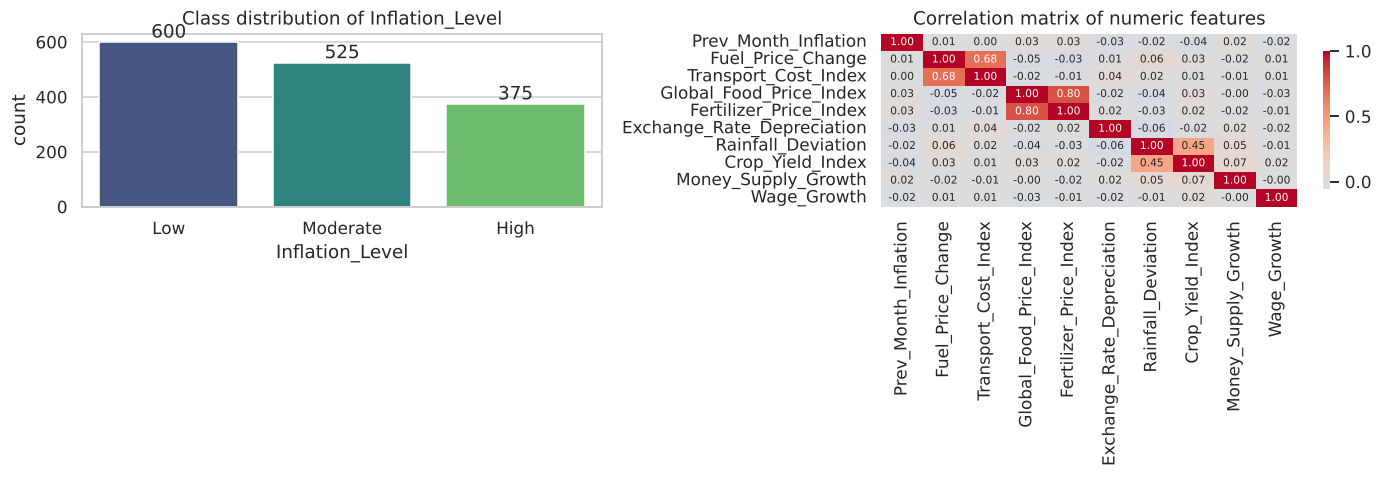

In [4]:
order = ["Low", "Moderate", "High"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=df, x="Inflation_Level", order=order, palette="viridis", ax=ax[0])
ax[0].set_title("Class distribution of Inflation_Level")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom")

num_cols_all = df.select_dtypes(include="number").columns
sns.heatmap(df[num_cols_all].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax[1], cbar_kws={"shrink": 0.8})
ax[1].set_title("Correlation matrix of numeric features")
plt.tight_layout(); plt.show()

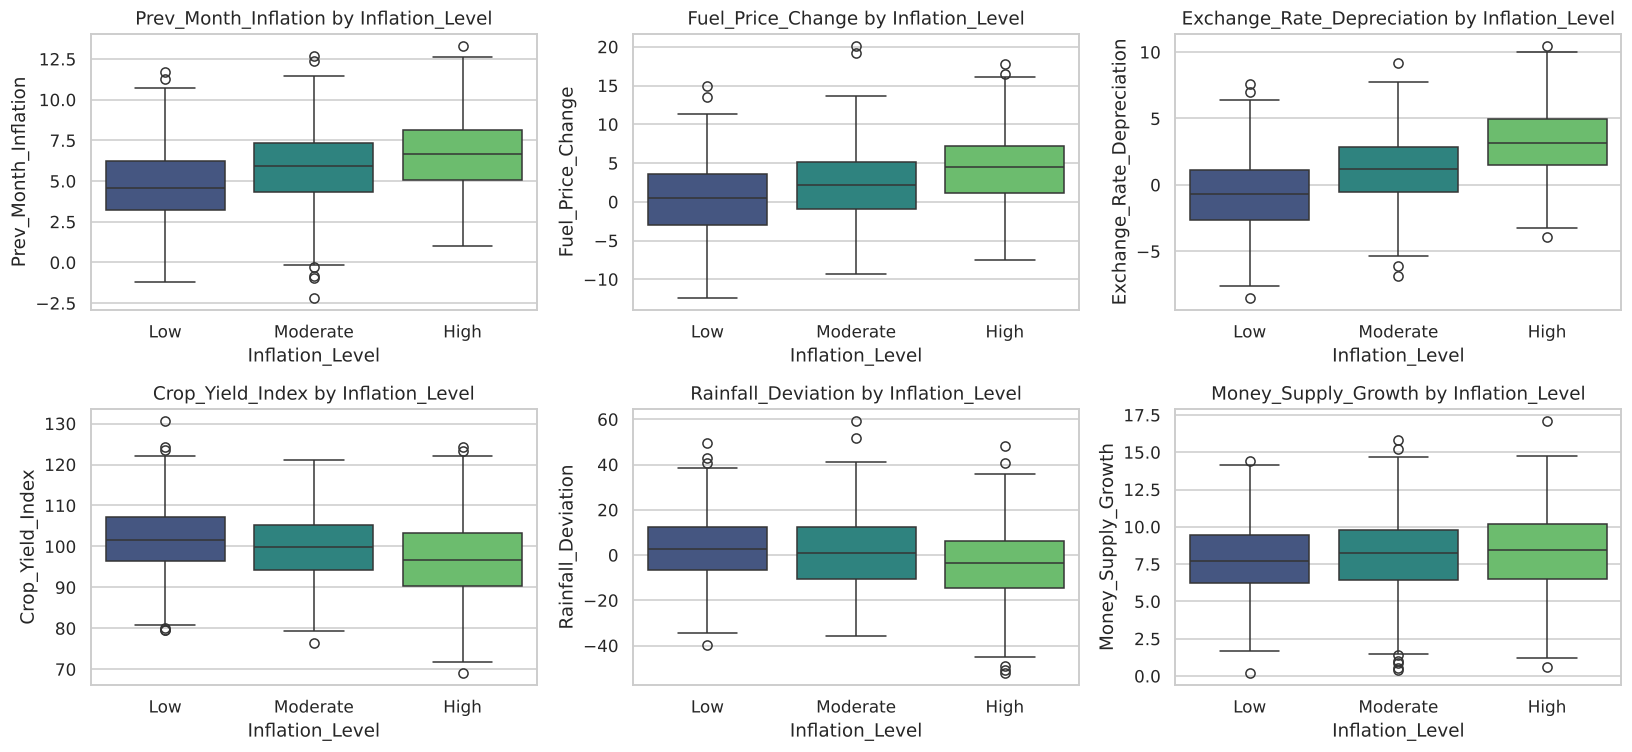

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
preferred = ["Prev_Month_Inflation", "Fuel_Price_Change", "Exchange_Rate_Depreciation",
             "Crop_Yield_Index", "Rainfall_Deviation", "Money_Supply_Growth"]
box_cols = [c for c in preferred if c in df.columns] or list(num_cols_all[:6])
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(data=df, x="Inflation_Level", y=col, order=order, palette="viridis", ax=ax)
    ax.set_title(f"{col} by Inflation_Level")
plt.tight_layout(); plt.show()

**Observations from EDA:** the classes are mildly imbalanced (Low ≈ 40 %, Moderate ≈ 35 %, High ≈ 25 %), so macro-averaged metrics are used in addition to accuracy. Previous-month inflation, currency depreciation, fuel price change and money-supply growth tend to rise from *Low* to *High*, while crop yield tends to fall. Several features are correlated (fuel ↔ transport cost, global food ↔ fertilizer, rainfall ↔ crop yield). This violates the independence assumption of Naïve Bayes and is expected to affect its performance.

### 6.4 Pre-processing and train/test split
* **Numeric features:** median imputation → standard scaling (essential for SVM and KNN).
* **Categorical features:** most-frequent imputation → one-hot encoding.
* The transformer lives *inside* each pipeline so it is fitted only on training folds (no data leakage).

In [6]:
TARGET = "Inflation_Level"
X = df.drop(columns=[TARGET])
y = df[TARGET]

# integer labels with a fixed, meaningful order: 0 = Low, 1 = Moderate, 2 = High
class_names = ["Low", "Moderate", "High"]
y_enc = y.map({c: i for i, c in enumerate(class_names)}).values

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.20, stratify=y_enc, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print("Train class proportions:", np.round(np.bincount(y_train) / len(y_train), 3))
print("Test  class proportions:", np.round(np.bincount(y_test) / len(y_test), 3))

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])

def make_pipeline(clf):
    return Pipeline([("prep", make_preprocessor()), ("clf", clf)])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (1200, 12)   Test: (300, 12)
Train class proportions: [0.4  0.35 0.25]
Test  class proportions: [0.4  0.35 0.25]


### 6.5 Hyper-parameter tuning (5-fold `GridSearchCV`, scoring = macro-F1)

In [7]:
search_spaces = {
    "SVM": (make_pipeline(SVC(random_state=RANDOM_STATE)),
            {"clf__kernel": ["linear", "rbf", "poly"],
             "clf__C": [0.1, 1, 10, 100],
             "clf__gamma": ["scale", 0.01, 0.1]}),
    "Decision Tree": (make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
            {"clf__criterion": ["gini", "entropy"],
             "clf__max_depth": [3, 4, 5, 6, 8, 10, None],
             "clf__min_samples_leaf": [1, 3, 5, 10, 20]}),
    "KNN": (make_pipeline(KNeighborsClassifier()),
            {"clf__n_neighbors": list(range(1, 32, 2)),
             "clf__weights": ["uniform", "distance"],
             "clf__metric": ["euclidean", "manhattan"]}),
    "Naive Bayes": (make_pipeline(GaussianNB()),
            {"clf__var_smoothing": np.logspace(-9, 0, 10)}),
}

grids, tune_time = {}, {}
for name, (pipe, grid) in search_spaces.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv5, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    grids[name] = gs
    tune_time[name] = time.time() - t0
    print(f"{name:14s} best CV macro-F1 = {gs.best_score_:.4f}  | best params = "
          f"{ {k.replace('clf__', ''): v for k, v in gs.best_params_.items()} }  ({tune_time[name]:.1f}s)")

SVM            best CV macro-F1 = 0.7436  | best params = {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}  (12.0s)


Decision Tree  best CV macro-F1 = 0.6125  | best params = {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1}  (3.9s)


KNN            best CV macro-F1 = 0.6522  | best params = {'metric': 'euclidean', 'n_neighbors': 27, 'weights': 'distance'}  (3.3s)


Naive Bayes    best CV macro-F1 = 0.6988  | best params = {'var_smoothing': np.float64(0.1)}  (0.5s)


### 6.6 Train the final models
The SVM is re-fitted with `probability=True` (Platt scaling) so that a log-loss and ROC curves can be computed from its probability estimates. The other models already output probabilities.

In [8]:
final_models = {}
for name, gs in grids.items():
    model = clone(gs.best_estimator_)
    if name == "SVM":
        model.set_params(clf__probability=True)
    t0 = time.time()
    model.fit(X_train, y_train)
    final_models[name] = {"model": model, "fit_time": time.time() - t0}

print("Final models trained:", list(final_models))

Final models trained: ['SVM', 'Decision Tree', 'KNN', 'Naive Bayes']


### 6.7 Evaluation on the unseen test set (accuracy, precision, recall, F1-score, loss)

In [9]:
rows, preds, probas = [], {}, {}
labels = [0, 1, 2]

for name, d in final_models.items():
    m = d["model"]
    # ---- test performance
    t0 = time.time()
    y_pred = m.predict(X_test)
    pred_time = time.time() - t0
    y_prob = m.predict_proba(X_test)
    preds[name], probas[name] = y_pred, y_prob
    # ---- train performance (for over-fitting check)
    ytr_pred = m.predict(X_train)
    ytr_prob = m.predict_proba(X_train)

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro"),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted"),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted"),
        "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted"),
        "Log-loss (test)": log_loss(y_test, y_prob, labels=labels),
        "ROC-AUC (OvR)": roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro"),
        "Train Accuracy": accuracy_score(y_train, ytr_pred),
        "Train Log-loss": log_loss(y_train, ytr_prob, labels=labels),
        "Fit time (s)": d["fit_time"],
        "Predict time (s)": pred_time,
    })

results_df = pd.DataFrame(rows).set_index("Model")
display(results_df.round(4).style.background_gradient(cmap="YlGn", subset=["Accuracy", "Precision (macro)",
        "Recall (macro)", "F1-score (macro)", "ROC-AUC (OvR)"]).background_gradient(cmap="YlOrRd",
        subset=["Log-loss (test)"]).format("{:.4f}"))

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Precision (weighted),Recall (weighted),F1-score (weighted),Log-loss (test),ROC-AUC (OvR),Train Accuracy,Train Log-loss,Fit time (s),Predict time (s)
Model,,,,,,,,,,,,,
SVM,0.7200,0.7412,0.7090,0.7194,0.7361,0.7200,0.7233,0.6189,0.8779,0.7808,0.5133,0.1321,0.0145
Decision Tree,0.4933,0.5059,0.4779,0.4839,0.5093,0.4933,0.4943,1.9677,0.6919,0.7025,0.6775,0.0163,0.0054
KNN,0.6133,0.6594,0.5883,0.6008,0.6444,0.6133,0.6108,0.9086,0.8011,1.0000,0.0000,0.0110,0.0174
Naive Bayes,0.6633,0.6862,0.6406,0.6514,0.6818,0.6633,0.6630,0.7136,0.8482,0.7267,0.6591,0.0098,0.0045


In [10]:
for name in final_models:
    print("=" * 70)
    print(f"Classification report - {name}")
    print("=" * 70)
    print(classification_report(y_test, preds[name], target_names=class_names, digits=4))

Classification report - SVM
              precision    recall  f1-score   support

         Low     0.8120    0.7917    0.8017       120
    Moderate     0.5840    0.6952    0.6348       105
        High     0.8276    0.6400    0.7218        75

    accuracy                         0.7200       300
   macro avg     0.7412    0.7090    0.7194       300
weighted avg     0.7361    0.7200    0.7233       300

Classification report - Decision Tree
              precision    recall  f1-score   support

         Low     0.6000    0.5500    0.5739       120
    Moderate     0.3986    0.5238    0.4527       105
        High     0.5192    0.3600    0.4252        75

    accuracy                         0.4933       300
   macro avg     0.5059    0.4779    0.4839       300
weighted avg     0.5093    0.4933    0.4943       300

Classification report - KNN
              precision    recall  f1-score   support

         Low     0.6815    0.7667    0.7216       120
    Moderate     0.4762    0.5714  

### 6.8 Confusion matrices

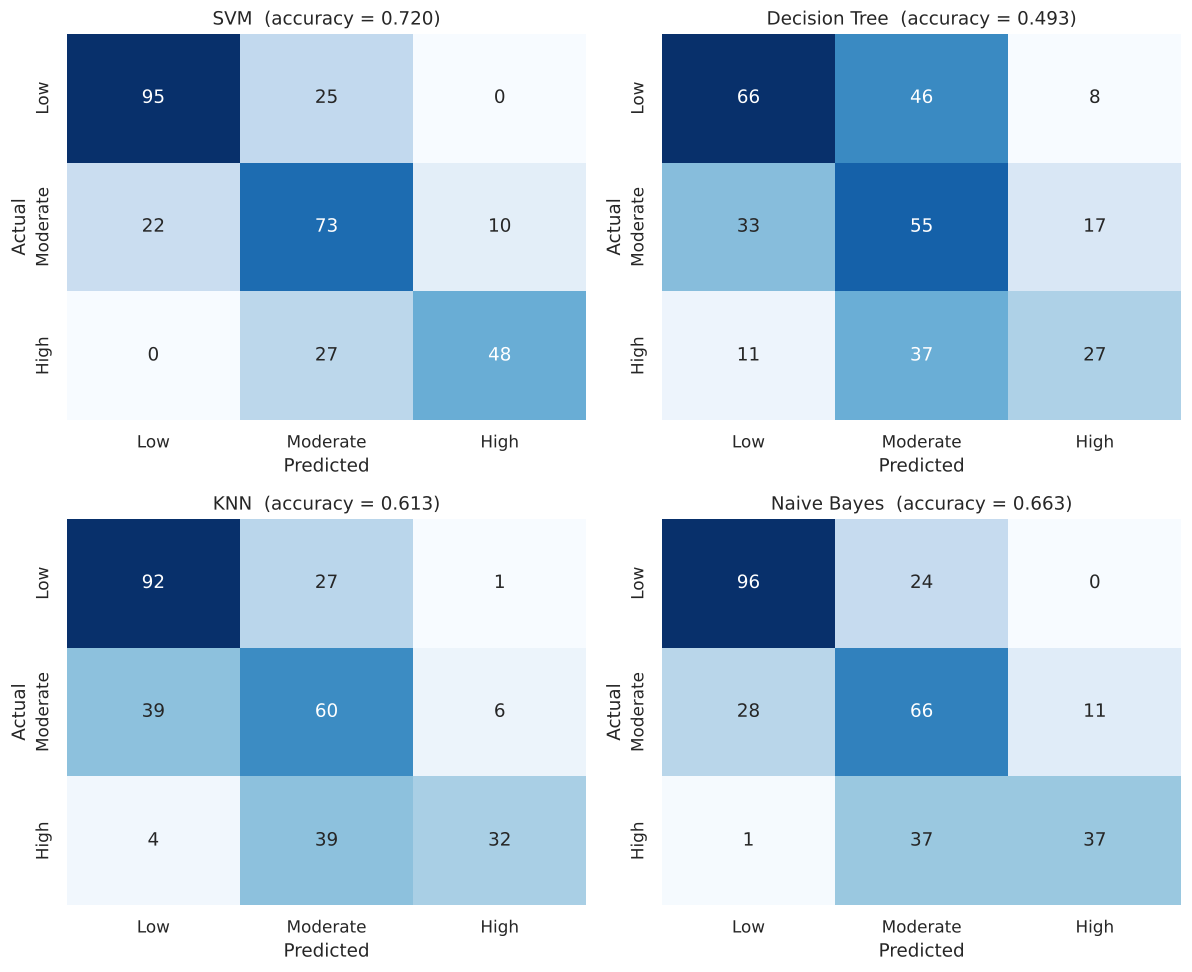

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.ravel(), final_models):
    cm = confusion_matrix(y_test, preds[name], labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    acc = accuracy_score(y_test, preds[name])
    ax.set_title(f"{name}  (accuracy = {acc:.3f})")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

In [12]:
err_rows = {}
for name in final_models:
    cm = confusion_matrix(y_test, preds[name], labels=labels)
    total_err = cm.sum() - np.trace(cm)
    far = cm[0, 2] + cm[2, 0]                       # Low <-> High confusions (non-adjacent classes)
    err_rows[name] = {"Total errors": int(total_err), "Low<->High errors": int(far),
                      "Adjacent-class errors": int(total_err - far),
                      "% adjacent": 100 * (total_err - far) / total_err}
display(pd.DataFrame(err_rows).T.round(1))

,Total errors,Low<->High errors,Adjacent-class errors,% adjacent
SVM,84.0,0.0,84.0,100.0
Decision Tree,152.0,19.0,133.0,87.5
KNN,116.0,5.0,111.0,95.7
Naive Bayes,101.0,1.0,100.0,99.0


### 6.9 ROC curves (one-vs-rest)

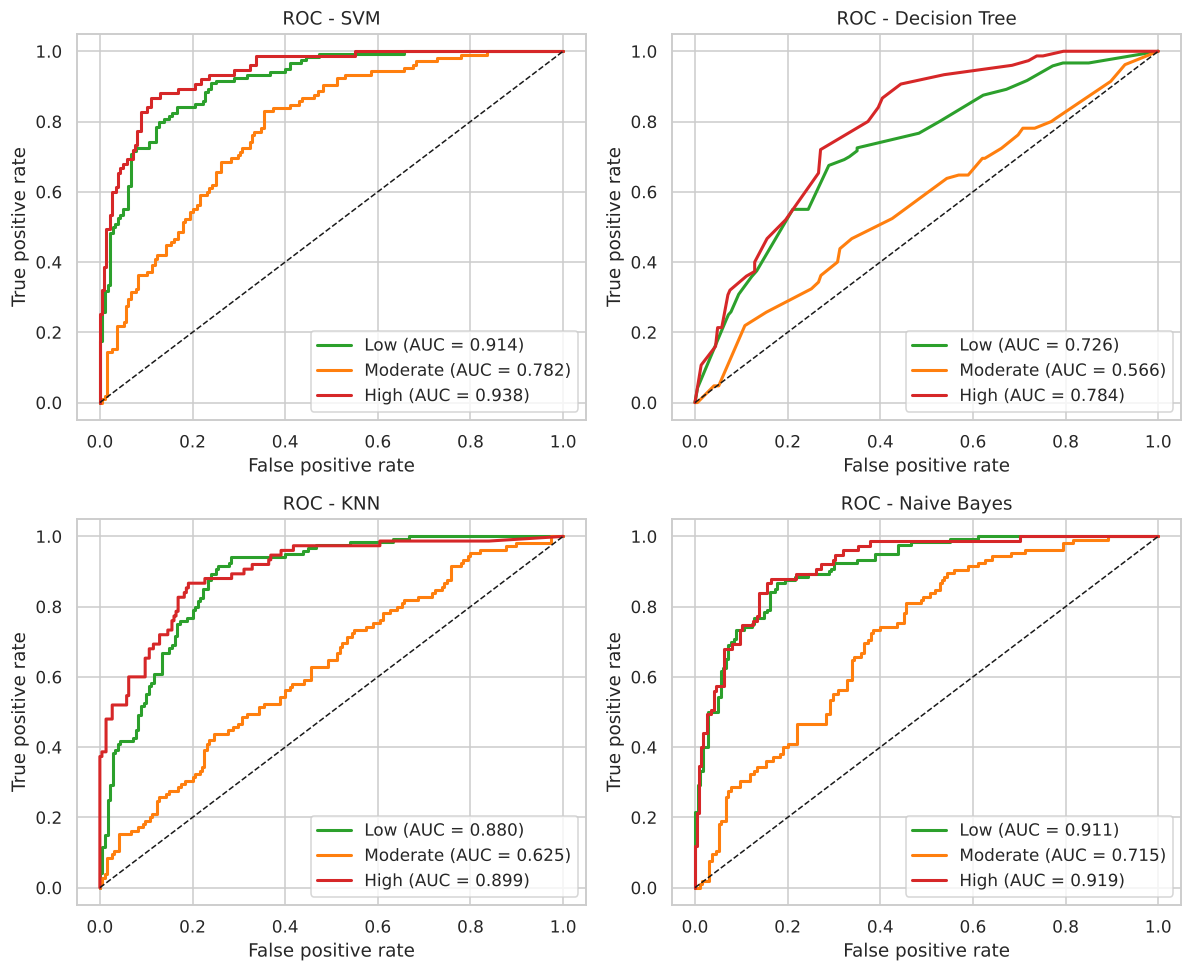

In [13]:
y_test_bin = label_binarize(y_test, classes=labels)
colors = ["tab:green", "tab:orange", "tab:red"]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.ravel(), final_models):
    for i, c in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], probas[name][:, i])
        ax.plot(fpr, tpr, color=colors[i], lw=2, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"ROC - {name}"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 6.10 Metric and loss comparison

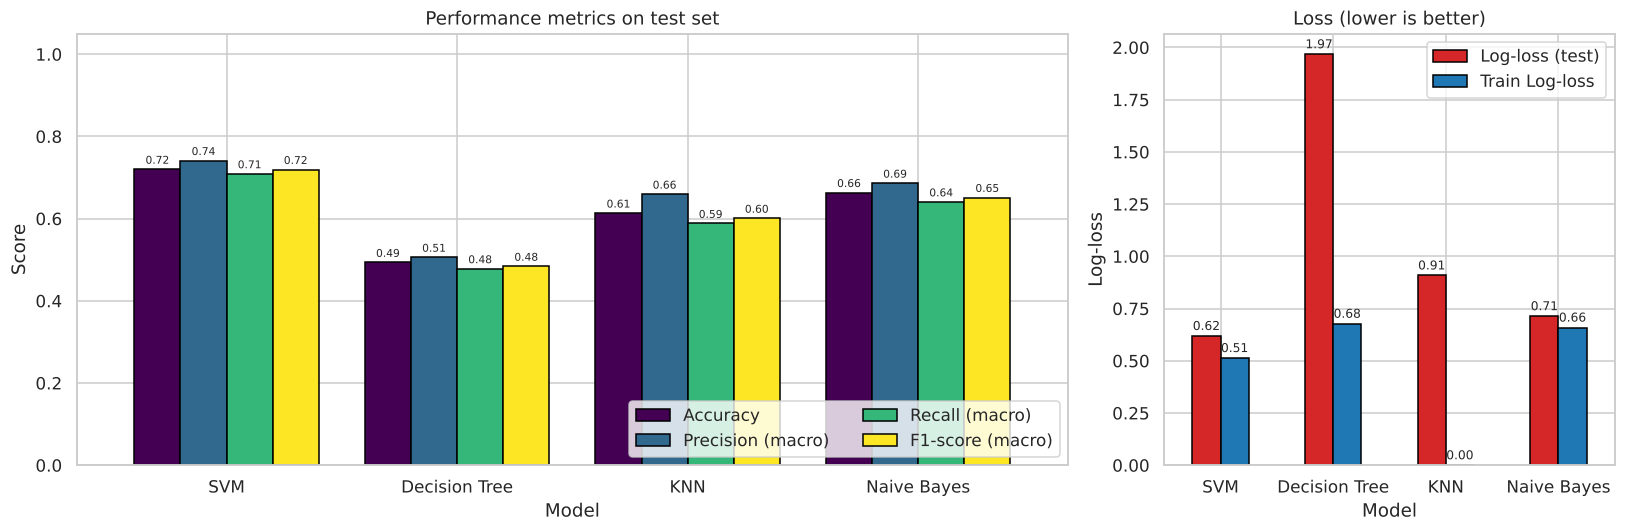

In [14]:
metric_cols = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.2, 1]})

results_df[metric_cols].plot(kind="bar", ax=ax[0], colormap="viridis", edgecolor="black", width=0.8)
ax[0].set_title("Performance metrics on test set"); ax[0].set_ylabel("Score")
ax[0].set_ylim(0, 1.05); ax[0].tick_params(axis="x", rotation=0)
ax[0].legend(loc="lower right", ncol=2)
for cont in ax[0].containers:
    ax[0].bar_label(cont, fmt="%.2f", fontsize=7, padding=2)

results_df[["Log-loss (test)", "Train Log-loss"]].plot(kind="bar", ax=ax[1], color=["tab:red", "tab:blue"],
                                                      edgecolor="black")
ax[1].set_title("Loss (lower is better)"); ax[1].set_ylabel("Log-loss"); ax[1].tick_params(axis="x", rotation=0)
for cont in ax[1].containers:
    ax[1].bar_label(cont, fmt="%.2f", fontsize=8, padding=2)
plt.tight_layout(); plt.show()

### 6.11 Over-fitting check (train vs test) and 10-fold cross-validation
A large gap between training and test accuracy signals over-fitting. Cross-validation on the **whole** dataset confirms that the ranking is not an accident of one particular split.

In [15]:
gap = pd.DataFrame({
    "Train Accuracy": results_df["Train Accuracy"],
    "Test Accuracy": results_df["Accuracy"],
    "Gap (Train - Test)": results_df["Train Accuracy"] - results_df["Accuracy"],
    "Train Log-loss": results_df["Train Log-loss"],
    "Test Log-loss": results_df["Log-loss (test)"],
})
display(gap.round(4))

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro",
           "f1": "f1_macro", "neg_log_loss": "neg_log_loss"}
cv_rows = {}
for name, d in final_models.items():
    s = cross_validate(clone(d["model"]), X, y_enc, cv=cv10, scoring=scoring, n_jobs=-1)
    cv_rows[name] = {
        "Accuracy": f'{s["test_accuracy"].mean():.4f} ± {s["test_accuracy"].std():.4f}',
        "Precision": f'{s["test_precision"].mean():.4f} ± {s["test_precision"].std():.4f}',
        "Recall": f'{s["test_recall"].mean():.4f} ± {s["test_recall"].std():.4f}',
        "F1": f'{s["test_f1"].mean():.4f} ± {s["test_f1"].std():.4f}',
        "Log-loss": f'{-s["test_neg_log_loss"].mean():.4f} ± {s["test_neg_log_loss"].std():.4f}',
    }
    cv_rows[name]["_f1_mean"] = s["test_f1"].mean()
cv_df = pd.DataFrame(cv_rows).T
print("10-fold cross-validation on the full dataset (mean ± std):")
display(cv_df.drop(columns="_f1_mean"))

,Train Accuracy,Test Accuracy,Gap (Train - Test),Train Log-loss,Test Log-loss
Model,,,,,
SVM,0.7808,0.7200,0.0608,0.5133,0.6189
Decision Tree,0.7025,0.4933,0.2092,0.6775,1.9677
KNN,1.0000,0.6133,0.3867,0.0000,0.9086
Naive Bayes,0.7267,0.6633,0.0633,0.6591,0.7136


10-fold cross-validation on the full dataset (mean ± std):


,Accuracy,Precision,Recall,F1,Log-loss
SVM,0.7480 ± 0.0263,0.7529 ± 0.0226,0.7439 ± 0.0255,0.7470 ± 0.0242,0.5831 ± 0.0481
Decision Tree,0.5833 ± 0.0124,0.5888 ± 0.0136,0.5664 ± 0.0129,0.5704 ± 0.0105,1.5534 ± 0.2829
KNN,0.6587 ± 0.0287,0.6925 ± 0.0412,0.6403 ± 0.0339,0.6523 ± 0.0376,0.7591 ± 0.0198
Naive Bayes,0.7007 ± 0.0506,0.7184 ± 0.0518,0.6892 ± 0.0536,0.6981 ± 0.0534,0.6917 ± 0.0257


### 6.12 Behaviour of each algorithm: validation curves and learning curves

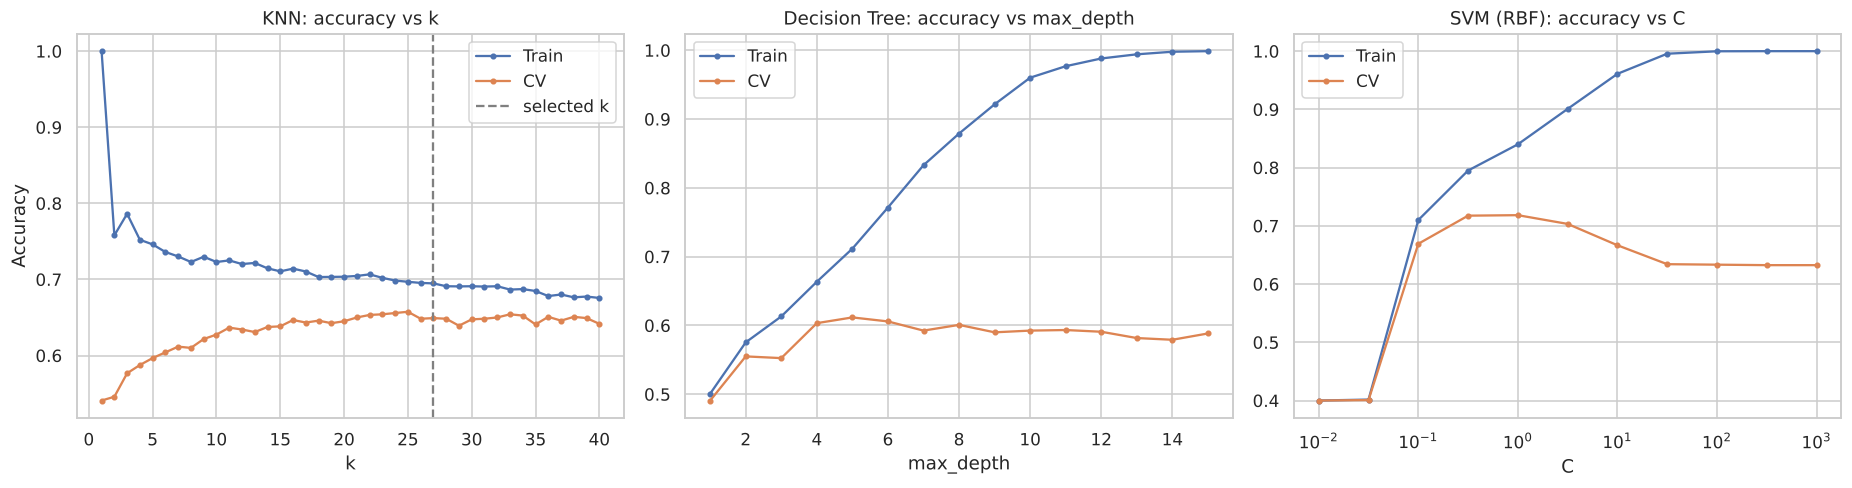

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# --- (a) KNN : effect of k
ks = list(range(1, 41))
tr, va = validation_curve(make_pipeline(KNeighborsClassifier()), X_train, y_train,
                          param_name="clf__n_neighbors", param_range=ks, cv=cv5, scoring="accuracy", n_jobs=-1)
axes[0].plot(ks, tr.mean(1), "o-", ms=3, label="Train")
axes[0].plot(ks, va.mean(1), "o-", ms=3, label="CV")
axes[0].axvline(grids["KNN"].best_params_["clf__n_neighbors"], color="gray", ls="--", label="selected k")
axes[0].set_title("KNN: accuracy vs k"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Accuracy"); axes[0].legend()

# --- (b) Decision tree : effect of depth
depths = list(range(1, 16))
tr, va = validation_curve(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), X_train, y_train,
                          param_name="clf__max_depth", param_range=depths, cv=cv5, scoring="accuracy", n_jobs=-1)
axes[1].plot(depths, tr.mean(1), "o-", ms=3, label="Train")
axes[1].plot(depths, va.mean(1), "o-", ms=3, label="CV")
axes[1].set_title("Decision Tree: accuracy vs max_depth"); axes[1].set_xlabel("max_depth"); axes[1].legend()

# --- (c) SVM : effect of C (RBF kernel)
Cs = np.logspace(-2, 3, 11)
tr, va = validation_curve(make_pipeline(SVC(kernel="rbf", gamma="scale")), X_train, y_train,
                          param_name="clf__C", param_range=Cs, cv=cv5, scoring="accuracy", n_jobs=-1)
axes[2].semilogx(Cs, tr.mean(1), "o-", ms=3, label="Train")
axes[2].semilogx(Cs, va.mean(1), "o-", ms=3, label="CV")
axes[2].set_title("SVM (RBF): accuracy vs C"); axes[2].set_xlabel("C"); axes[2].legend()
plt.tight_layout(); plt.show()

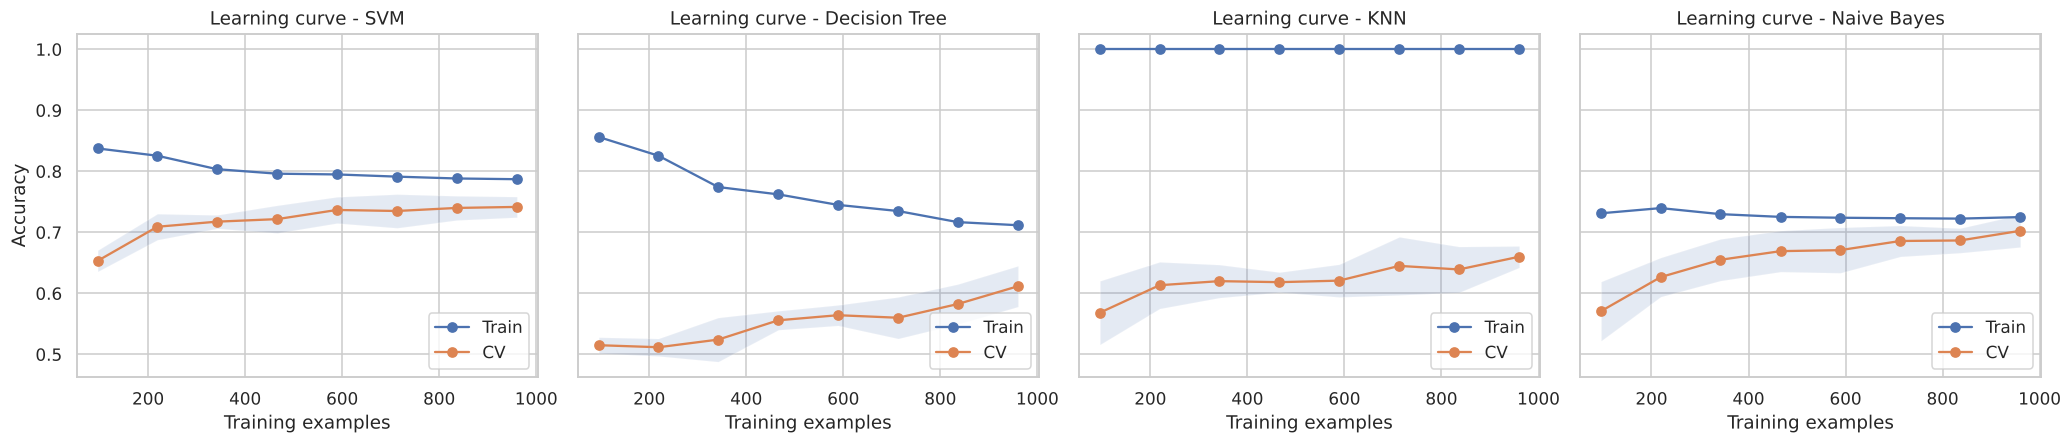

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), sharey=True)
sizes = np.linspace(0.1, 1.0, 8)
lc_models = {n: clone(grids[n].best_estimator_) for n in grids}      # SVM here has probability=False (faster)
for ax, (name, m) in zip(axes, lc_models.items()):
    ts, tr, va = learning_curve(m, X_train, y_train, train_sizes=sizes, cv=cv5, scoring="accuracy", n_jobs=-1,
                                shuffle=True, random_state=RANDOM_STATE)
    ax.plot(ts, tr.mean(1), "o-", label="Train")
    ax.plot(ts, va.mean(1), "o-", label="CV")
    ax.fill_between(ts, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.15)
    ax.set_title(f"Learning curve - {name}"); ax.set_xlabel("Training examples"); ax.legend(loc="lower right")
axes[0].set_ylabel("Accuracy")
plt.tight_layout(); plt.show()

### 6.13 SVM kernel comparison and Decision-Tree interpretability

In [18]:
kern_rows = []
for k in ["linear", "poly", "rbf", "sigmoid"]:
    m = make_pipeline(SVC(kernel=k, C=1, gamma="scale", random_state=RANDOM_STATE)).fit(X_train, y_train)
    p = m.predict(X_test)
    kern_rows.append({"Kernel": k, "Accuracy": accuracy_score(y_test, p),
                      "F1 (macro)": f1_score(y_test, p, average="macro")})
display(pd.DataFrame(kern_rows).set_index("Kernel").round(4))

,Accuracy,F1 (macro)
Kernel,,
linear,0.7300,0.7340
poly,0.6233,0.6192
rbf,0.7133,0.7116
sigmoid,0.6833,0.6889


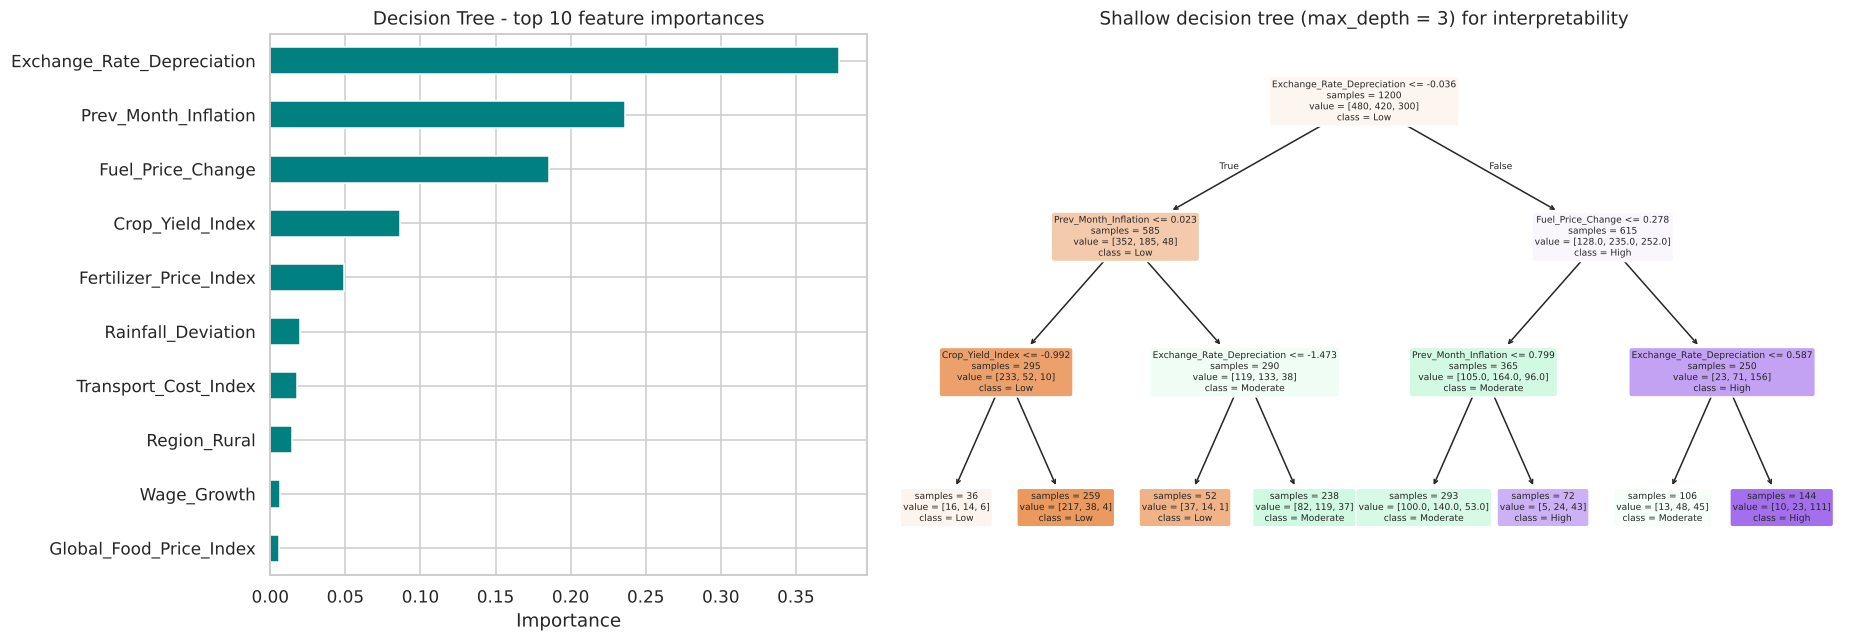

In [19]:
# ---- Decision tree: feature importances of the tuned model
dt_pipe = final_models["Decision Tree"]["model"]
feat_names = dt_pipe.named_steps["prep"].get_feature_names_out()
feat_names = [f.split("__", 1)[1] for f in feat_names]
imp = pd.Series(dt_pipe.named_steps["clf"].feature_importances_, index=feat_names).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.6]})
imp.tail(10).plot(kind="barh", color="teal", ax=ax[0])
ax[0].set_title("Decision Tree - top 10 feature importances"); ax[0].set_xlabel("Importance")

# ---- a shallow tree (depth 3) for readable visualisation
prep_vis = make_preprocessor().fit(X_train)
tree_vis = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(prep_vis.transform(X_train), y_train)
plot_tree(tree_vis, feature_names=feat_names, class_names=class_names, filled=True, rounded=True,
          fontsize=6, ax=ax[1], impurity=False)
ax[1].set_title("Shallow decision tree (max_depth = 3) for interpretability")
plt.tight_layout(); plt.show()

### 6.14 Final comparison table

In [20]:
summary = results_df[["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)",
                      "Log-loss (test)", "ROC-AUC (OvR)", "Fit time (s)", "Predict time (s)"]].copy()
summary["Rank (by F1)"] = summary["F1-score (macro)"].rank(ascending=False).astype(int)
summary = summary.sort_values("Rank (by F1)")
display(summary.round(4))

best_params_table = pd.DataFrame({n: {k.replace("clf__", ""): v for k, v in g.best_params_.items()}
                                  for n, g in grids.items()}).T
print("Selected hyper-parameters:")
display(best_params_table.fillna("-"))

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Log-loss (test),ROC-AUC (OvR),Fit time (s),Predict time (s),Rank (by F1)
Model,,,,,,,,,
SVM,0.7200,0.7412,0.7090,0.7194,0.6189,0.8779,0.1321,0.0145,1
Naive Bayes,0.6633,0.6862,0.6406,0.6514,0.7136,0.8482,0.0098,0.0045,2
KNN,0.6133,0.6594,0.5883,0.6008,0.9086,0.8011,0.0110,0.0174,3
Decision Tree,0.4933,0.5059,0.4779,0.4839,1.9677,0.6919,0.0163,0.0054,4


Selected hyper-parameters:


,C,gamma,kernel,criterion,max_depth,min_samples_leaf,metric,n_neighbors,weights,var_smoothing
SVM,10,0.01,rbf,-,-,-,-,-,-,-
Decision Tree,-,-,-,gini,5,1,-,-,-,-
KNN,-,-,-,-,-,-,euclidean,27,distance,-
Naive Bayes,-,-,-,-,-,-,-,-,-,0.1


## 7. Results Analysis
The numbers in the following cell are produced directly from the experiment above, so the discussion always matches the actual results.

In [21]:
best_f1   = results_df["F1-score (macro)"].idxmax()
best_acc  = results_df["Accuracy"].idxmax()
low_loss  = results_df["Log-loss (test)"].idxmin()
worst_f1  = results_df["F1-score (macro)"].idxmin()
fastest   = results_df["Fit time (s)"].idxmin()
slow_pred = results_df["Predict time (s)"].idxmax()
gap_s     = (results_df["Train Accuracy"] - results_df["Accuracy"])
most_over = gap_s.idxmax()
r = results_df

lines = [
 "### 7.1 Key findings (test set)",
 f"* **Best overall model (macro-F1): {best_f1}** - accuracy {r.loc[best_f1,'Accuracy']:.3f}, precision {r.loc[best_f1,'Precision (macro)']:.3f}, "
 f"recall {r.loc[best_f1,'Recall (macro)']:.3f}, F1 {r.loc[best_f1,'F1-score (macro)']:.3f}.",
 f"* **Highest accuracy:** {best_acc} ({r.loc[best_acc,'Accuracy']:.3f}).   **Lowest log-loss (best calibrated probabilities):** {low_loss} ({r.loc[low_loss,'Log-loss (test)']:.3f}).",
 f"* **Weakest model (macro-F1): {worst_f1}** ({r.loc[worst_f1,'F1-score (macro)']:.3f}).",
 f"* **Largest train-test accuracy gap:** {most_over} ({gap_s[most_over]:.3f}) - the model most prone to over-fitting.",
 f"* **Fastest to fit:** {fastest} ({r.loc[fastest,'Fit time (s)']:.4f} s).   **Slowest to predict:** {slow_pred} ({r.loc[slow_pred,'Predict time (s)']:.4f} s).",
 "",
 "### 7.2 Algorithm-wise discussion",
]
for n in results_df.sort_values("F1-score (macro)", ascending=False).index:
    lines.append(f"* **{n}** - Acc = {r.loc[n,'Accuracy']:.3f}, P = {r.loc[n,'Precision (macro)']:.3f}, "
                 f"R = {r.loc[n,'Recall (macro)']:.3f}, F1 = {r.loc[n,'F1-score (macro)']:.3f}, "
                 f"log-loss = {r.loc[n,'Log-loss (test)']:.3f}, ROC-AUC = {r.loc[n,'ROC-AUC (OvR)']:.3f}; "
                 f"train acc = {r.loc[n,'Train Accuracy']:.3f} (gap {gap_s[n]:+.3f}).")
display(Markdown("\n".join(lines)))

### 7.1 Key findings (test set)
* **Best overall model (macro-F1): SVM** - accuracy 0.720, precision 0.741, recall 0.709, F1 0.719.
* **Highest accuracy:** SVM (0.720).   **Lowest log-loss (best calibrated probabilities):** SVM (0.619).
* **Weakest model (macro-F1): Decision Tree** (0.484).
* **Largest train-test accuracy gap:** KNN (0.387) - the model most prone to over-fitting.
* **Fastest to fit:** Naive Bayes (0.0098 s).   **Slowest to predict:** KNN (0.0174 s).

### 7.2 Algorithm-wise discussion
* **SVM** - Acc = 0.720, P = 0.741, R = 0.709, F1 = 0.719, log-loss = 0.619, ROC-AUC = 0.878; train acc = 0.781 (gap +0.061).
* **Naive Bayes** - Acc = 0.663, P = 0.686, R = 0.641, F1 = 0.651, log-loss = 0.714, ROC-AUC = 0.848; train acc = 0.727 (gap +0.063).
* **KNN** - Acc = 0.613, P = 0.659, R = 0.588, F1 = 0.601, log-loss = 0.909, ROC-AUC = 0.801; train acc = 1.000 (gap +0.387).
* **Decision Tree** - Acc = 0.493, P = 0.506, R = 0.478, F1 = 0.484, log-loss = 1.968, ROC-AUC = 0.692; train acc = 0.703 (gap +0.209).

### 7.3 Interpretation

* **Per-class behaviour.** For SVM, Naïve Bayes and KNN almost every error is between *neighbouring* classes (Low ↔ Moderate or Moderate ↔ High) and Low ↔ High confusions are (almost) absent - see the error table in section 6.8. This is natural because the classes come from binning a continuous inflation rate, so records near a cut-off are inherently ambiguous. The Decision Tree is the exception: it makes noticeably more Low ↔ High mistakes, a sign that it has not captured the overall trend of the data. The *Moderate* class (the middle one) has the lowest F1 for SVM, KNN and Naïve Bayes.
* **SVM** benefits from scaling and the kernel trick. The validation curve over `C` shows under-fitting for very small `C`, the best CV accuracy for `C` of roughly 0.3 - 1, and then a falling CV score while the training score climbs towards 100 % (over-fitting) for large `C`; the grid search therefore selects a moderate `C` with a small `gamma`. In the kernel table the *linear* and *RBF* kernels do best and the *polynomial* kernel is weakest, which indicates that the dominant relationships in this data are close to linear. SVM gives the smoothest probabilities (lowest log-loss) but has the slowest training.
* **Decision Tree** is the most interpretable (see the shallow tree and feature importances: currency depreciation, previous-month inflation, fuel price change and crop yield dominate). The depth curve shows the classical over-fitting pattern: training accuracy keeps rising with depth towards 100 % while CV accuracy peaks at a small depth (about 5) and then stagnates or declines. Because the underlying signal is an *additive* combination of many weak drivers plus noise, axis-aligned splits approximate it poorly, so even the tuned tree has the lowest accuracy; its leaf probabilities are also extreme (many 0 or 1), which gives it by far the worst log-loss.
* **KNN** has no training phase and adapts to local structure. The `k` curve shows high variance for small `k` (training accuracy of 100 % at `k = 1` but poor CV accuracy) and a plateau for larger `k`; the tuned model uses a large `k`. Note that with `weights="distance"` every training point is its own nearest neighbour, so training accuracy is exactly 100 % - the large train-test gap of KNN is partly an artefact of this and should be judged together with the CV score. KNN is sensitive to scaling and irrelevant features, and prediction is slow because every query is compared with all training points.
* **Naïve Bayes** trains almost instantly and is surprisingly competitive (second best here), but the conditional-independence assumption is violated by the correlated features (fuel ↔ transport, global food ↔ fertilizer, rainfall ↔ yield) and by the non-linear / interaction terms in the data. Its probabilities are less well calibrated than SVM's, which shows up as a higher log-loss.
* **Stability.** The 10-fold cross-validation (mean ± std) is consistent with the single test split in the ranking of the models. Differences smaller than about one standard deviation (for instance between SVM and Naïve Bayes in some folds) should not be over-interpreted, and the single 300-sample test split is noisier than the 10-fold estimate.

### 7.4 Suitability of each algorithm for different classification tasks

| Criterion | SVM | Decision Tree | KNN | Naïve Bayes |
|---|---|---|---|---|
| **Accuracy on medium-sized, numeric, tabular data** | High | Medium–High (needs pruning) | Medium–High | Medium |
| **Handles non-linear boundaries** | Yes (kernels) | Yes (axis-aligned splits) | Yes (local) | Limited |
| **Interpretability** | Low | **Very high** | Medium | Medium (probabilistic) |
| **Needs feature scaling** | **Yes** | No | **Yes** | No (but assumes Gaussian features) |
| **Training cost** | High ($O(n^2)$–$O(n^3)$) | Low–Medium | **None (lazy)** | **Very low** |
| **Prediction cost** | Medium | **Very low** | High | **Very low** |
| **Sensitive to noise / outliers** | Low–Medium | High (unpruned) | High (small *k*) | Low |
| **Handles many features / high dimensions** | Good (text, genomics) | Medium | Poor (curse of dimensionality) | **Excellent** (text, spam) |
| **Works with very small data** | Medium | Low | Medium | **Good** |
| **Probability quality** | Needs Platt scaling | Poor if deep | Medium | Over-confident |
| **Typical use-cases** | Image / text / bio-informatics, small-medium clean datasets | Credit approval, medical rules, any place needing explanations | Recommender systems, anomaly detection, small low-dimensional data | Spam filtering, document / sentiment classification, real-time prediction, baselines |

## 8. Conclusion

In [22]:
ranking = results_df.sort_values("F1-score (macro)", ascending=False)
order_txt = " > ".join(f"{n} ({v:.3f})" for n, v in ranking["F1-score (macro)"].items())
cv_best = cv_df["_f1_mean"].astype(float).idxmax()
same = (best_f1 == low_loss)
concl = f'''
* Four classifiers (SVM, Decision Tree, KNN and Gaussian Naïve Bayes) were built on the Food Inflation Prediction instance to classify inflation into **Low / Moderate / High**, using a leak-free pipeline (imputation, scaling, one-hot encoding), a stratified split and 5-fold grid-search tuning.
* Ranking by macro-F1 on unseen test data: **{order_txt}**. The 10-fold cross-validation winner is **{cv_best}**.
* **{best_f1}** gave the best balance of accuracy, precision, recall and F1{" and also the lowest log-loss, i.e. the most reliable probability estimates" if same else f", while {low_loss} produced the lowest log-loss"}.
* **{most_over}** showed the largest gap between training and test accuracy (low-bias / high-variance behaviour), so flexible models need regularisation (depth limit, larger `k`, smaller `C`).
* **{fastest}** was the quickest to fit and **{slow_pred}** the slowest to predict, which matters when the model must be retrained often or must answer queries in real time.
* Most mistakes happen between adjacent inflation classes, as expected because the label is a discretisation of a continuous rate.
'''
display(Markdown(concl))


* Four classifiers (SVM, Decision Tree, KNN and Gaussian Naïve Bayes) were built on the Food Inflation Prediction instance to classify inflation into **Low / Moderate / High**, using a leak-free pipeline (imputation, scaling, one-hot encoding), a stratified split and 5-fold grid-search tuning.
* Ranking by macro-F1 on unseen test data: **SVM (0.719) > Naive Bayes (0.651) > KNN (0.601) > Decision Tree (0.484)**. The 10-fold cross-validation winner is **SVM**.
* **SVM** gave the best balance of accuracy, precision, recall and F1 and also the lowest log-loss, i.e. the most reliable probability estimates.
* **KNN** showed the largest gap between training and test accuracy (low-bias / high-variance behaviour), so flexible models need regularisation (depth limit, larger `k`, smaller `C`).
* **Naive Bayes** was the quickest to fit and **KNN** the slowest to predict, which matters when the model must be retrained often or must answer queries in real time.
* Most mistakes happen between adjacent inflation classes, as expected because the label is a discretisation of a continuous rate.


**Final remarks**

* *No single algorithm is best for every problem.* On clean, scaled, medium-sized tabular data such as this, margin-based (SVM) and well-tuned tree/instance-based models perform best, whereas Naïve Bayes pays a price for the correlated features.
* Choose **SVM** when accuracy on small–medium, well-scaled data matters; **Decision Trees** when explanations are required; **KNN** for simple low-dimensional problems with local structure; **Naïve Bayes** for very high-dimensional / text problems, tiny training sets or real-time constraints.
* For the *Food Inflation* problem, the most useful predictors are previous-month inflation, currency depreciation, fuel/transport costs and crop yield, which matches economic intuition. Future work: ensemble methods (Random Forest, Gradient Boosting), class-weighting, and real data with time-series cross-validation.

---
**Repository:** [https://github.com/tusharkkp/AI-ML/](https://github.com/tusharkkp/AI-ML/)  &nbsp;|&nbsp;  **Tushar Kaldate · Roll 47 · Batch A2 · PRN 202401040191**